# Student Placement AI - Placement Prediction System
**Subject:** Data Science-I (Term Work) &nbsp;|&nbsp; **Team:** Monani Meet (Roll 58), Bhingradiya Vasu (Roll 69)


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc, roc_auc_score


## Step 1 - Load the student placement data
We use the placement dataset: 120,000 student records with academic, skill, and project features.


In [2]:

df = pd.read_csv("student_placement_big.csv")
print("full shape:", df.shape)

df = df.sample(n=20000, random_state=42).reset_index(drop=True)
print("sample shape:", df.shape)
df.head()

full shape: (120000, 23)
sample shape: (20000, 23)


,student_id,gender,age,cgpa,10th_percentage,12th_percentage,backlogs,attendance_percentage,coding_score,aptitude_score,...,internship_months,certifications,hackathon_participation,programming_languages_known,dsa_skill_score,database_skill_score,web_development_skill,github_projects,extracurricular_score,placement_status
0,STU_72788,Male,23,7.03,66.7,65.8,0,87.4,57.4,64.6,...,0,3,0,1,48.3,51.6,58.9,1,65.4,Not Placed
1,STU_68219,Male,23,7.52,71.8,74.4,0,76.6,54.3,67.8,...,0,1,0,1,36.9,62.9,60.9,1,45.5,Not Placed
2,STU_55067,Female,22,7.79,78.4,78.8,0,82.9,77.0,67.7,...,0,2,0,5,65.7,56.6,92.3,4,53.4,Placed
3,STU_8169,Male,22,7.75,80.7,73.0,2,76.7,48.7,80.4,...,0,3,1,2,51.1,54.6,55.2,2,56.2,Not Placed
4,STU_30619,Male,22,6.71,78.9,60.4,0,82.5,68.3,63.5,...,0,2,1,3,71.3,62.6,61.8,2,64.4,Not Placed


## Step 2 - Exploratory Data Analysis (EDA)
Before modelling, we check the dataset structure, missing values, and summary distributions.


In [3]:

print("shape:", df.shape)
print("\nmissing values:\n", df.isnull().sum())
print("\nplaced vs not placed:\n", df["placement_status"].value_counts())

shape: (20000, 23)

missing values:
 student_id                     0
gender                         0
age                            0
cgpa                           0
10th_percentage                0
12th_percentage                0
backlogs                       0
attendance_percentage          0
coding_score                   0
aptitude_score                 0
communication_score            0
technical_skill_score          0
number_of_projects             0
internship_months              0
certifications                 0
hackathon_participation        0
programming_languages_known    0
dsa_skill_score                0
database_skill_score           0
web_development_skill          0
github_projects                0
extracurricular_score          0
placement_status               0
dtype: int64

placed vs not placed:
 placement_status
Placed        11477
Not Placed     8523
Name: count, dtype: int64


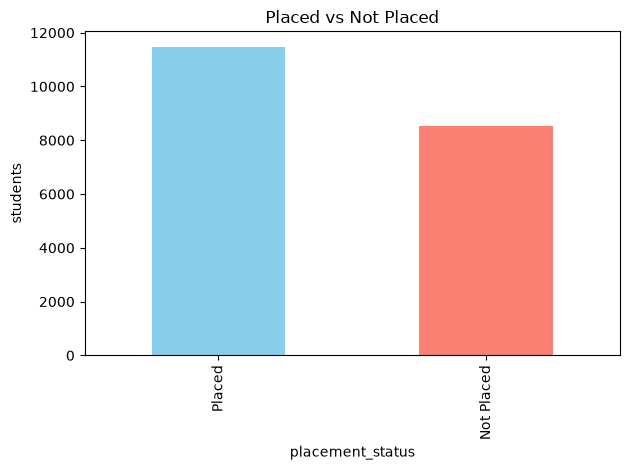

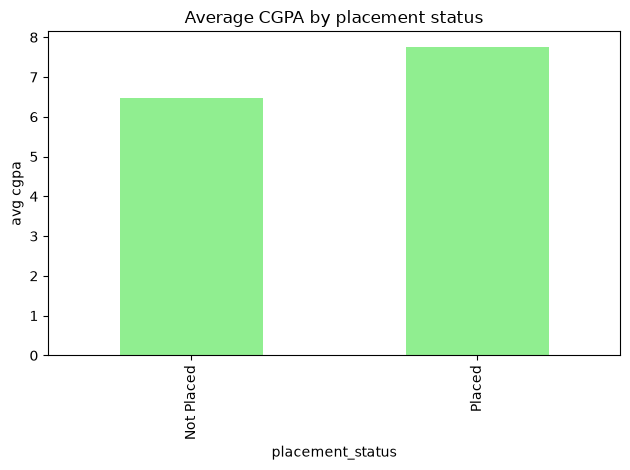

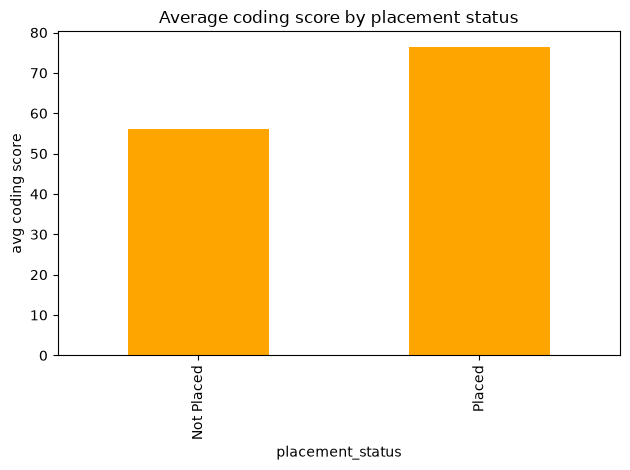

In [4]:
ax = df["placement_status"].value_counts().plot(kind="bar", color=["skyblue", "salmon"])
plt.title("Placed vs Not Placed")
plt.xlabel("placement_status"); plt.ylabel("students")
plt.tight_layout()
plt.show()

df.groupby("placement_status")["cgpa"].mean().plot(kind="bar", color="lightgreen")
plt.title("Average CGPA by placement status")
plt.xlabel("placement_status"); plt.ylabel("avg cgpa")
plt.tight_layout()
plt.show()

df.groupby("placement_status")["coding_score"].mean().plot(kind="bar", color="orange")
plt.title("Average coding score by placement status")
plt.xlabel("placement_status"); plt.ylabel("avg coding score")
plt.tight_layout()
plt.show()


## Step 3 - Feature engineering
Single columns do not tell the whole story, so we build three aggregated features:
- `academic_avg`: overall academics (CGPA * 10 + 10th % + 12th %) / 3
- `skill_avg`: average of skill scores (coding, aptitude, communication, technical, DSA, database, web-dev)
- `experience_score`: internship months + projects + certifications + hackathons + GitHub projects
We also drop `student_id` (identifier) and encode categorical variables into numeric values.


In [5]:

skill_cols = ["coding_score", "aptitude_score", "communication_score",
              "technical_skill_score", "dsa_skill_score",
              "database_skill_score", "web_development_skill"]

df["academic_avg"] = (df["cgpa"] * 10 + df["10th_percentage"] + df["12th_percentage"]) / 3
df["skill_avg"] = df[skill_cols].mean(axis=1)
df["experience_score"] = (df["internship_months"] + df["number_of_projects"]
                            + df["certifications"] + df["hackathon_participation"]
                            + df["github_projects"])

df = df.drop(columns=["student_id"])
df["placement_status"] = df["placement_status"].map({"Placed": 1, "Not Placed": 0})
df = pd.get_dummies(df, columns=["gender"], drop_first=True)

print("after feature engineering:", df.shape)
print(df[["academic_avg", "skill_avg", "experience_score", "placement_status"]].head())

after feature engineering: (20000, 26)
   academic_avg  skill_avg  experience_score  placement_status
0     67.600000  61.471429                 6                 0
1     73.800000  60.957143                 2                 0
2     78.366667  70.514286                 9                 1
3     77.066667  56.100000                 8                 0
4     68.800000  68.228571                 6                 0


## Step 4 - Train/test split and Feature Scaling
We split the data into 80% training and 20% testing sets.
Because algorithms like KNN, Logistic Regression, and SVM are sensitive to feature magnitudes, we standardize all features using `StandardScaler` (fit on train, transform on test).


In [6]:

X = df.drop(columns=["placement_status"])
y = df["placement_status"]
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

train: (16000, 25)  test: (4000, 25)


## Step 5 - Model Training and Evaluation (Supervised Learning)
We train six different classification models covered in the syllabus:
1. Logistic Regression
2. K-Nearest Neighbours (KNN)
3. Gaussian Naive Bayes
4. Decision Tree
5. Random Forest
6. Support Vector Machine (SVM)


In [7]:
print("\n===== TASK 1: classification -> placement_status =====")

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(),
}


===== TASK 1: classification -> placement_status =====


### Step 5b - Train models and calculate metrics


In [8]:
rows = []
trained = {}
predictions = {}
probabilities = {}

for name, m in models.items():
    m.fit(X_train_s, y_train)
    pred = m.predict(X_test_s)
    if hasattr(m, 'predict_proba'):
        prob = m.predict_proba(X_test_s)[:, 1]
    else:
        prob = m.decision_function(X_test_s)
    
    trained[name] = m
    predictions[name] = pred
    probabilities[name] = prob
    
    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred)
    rec = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc_auc = roc_auc_score(y_test, prob)
    
    rows.append({
        'model': name,
        'accuracy': round(acc, 4),
        'precision': round(prec, 4),
        'recall': round(rec, 4),
        'f1': round(f1, 4),
        'roc_auc': round(roc_auc, 4)
    })
    print(f"{name:20s} -> Accuracy: {acc:.4f} | ROC-AUC: {roc_auc:.4f}")

metrics = pd.DataFrame(rows).sort_values(by='accuracy', ascending=False).reset_index(drop=True)
metrics


Logistic Regression  -> Accuracy: 0.9360 | ROC-AUC: 0.9847


C:\Users\vasub\anaconda4\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\vasub\anaconda4\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\vasub\anaconda4\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\vasub\anaconda4\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\vasub\anaconda4\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

KNN                  -> Accuracy: 0.9015 | ROC-AUC: 0.9589
Naive Bayes          -> Accuracy: 0.9050 | ROC-AUC: 0.9738
Decision Tree        -> Accuracy: 0.8795 | ROC-AUC: 0.8776
Random Forest        -> Accuracy: 0.9223 | ROC-AUC: 0.9793
SVM                  -> Accuracy: 0.9357 | ROC-AUC: 0.9824


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.9360,0.9468,0.9419,0.9443,0.9847
1,SVM,0.9357,0.9464,0.9419,0.9441,0.9824
2,Random Forest,0.9223,0.9327,0.9323,0.9325,0.9793
3,Naive Bayes,0.9050,0.9377,0.8946,0.9156,0.9738
4,KNN,0.9015,0.9078,0.9228,0.9152,0.9589
5,Decision Tree,0.8795,0.8996,0.8902,0.8949,0.8776


## Step 6 - Feature Importance Analysis
Using the Random Forest model, we analyze which features carry the highest importance for predicting placement.


In [ ]:
print("\n===== TASK 2: analysis -> which factors matter most =====")

rf = trained["Random Forest"]
importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf.feature_importances_,
}).sort_values("importance", ascending=False)

print(importance.head(10))


===== TASK 2: analysis -> which factors matter most =====
                  feature  importance
21              skill_avg    0.185243
9   technical_skill_score    0.146333
15        dsa_skill_score    0.117303
6            coding_score    0.092164
1                    cgpa    0.083604
20           academic_avg    0.053872
22       experience_score    0.041634
7          aptitude_score    0.034867
4                backlogs    0.034724
2         10th_percentage    0.030820


## Step 7 - Comparison of Model Performance


In [10]:
print('=== COMPREHENSIVE MODEL COMPARISON (Syllabus Units 2 & 3) ===')
print(metrics.to_string(index=False))
winner = metrics.iloc[0]['model']
best_acc = metrics.iloc[0]['accuracy'] * 100
best_auc = metrics.iloc[0]['roc_auc']
print(f"\nBest Performing Model: {winner} (Accuracy = {best_acc:.2f}%, ROC-AUC = {best_auc:.4f})")


=== COMPREHENSIVE MODEL COMPARISON (Syllabus Units 2 & 3) ===
              model  accuracy  precision  recall     f1  roc_auc
Logistic Regression    0.9360     0.9468  0.9419 0.9443   0.9847
                SVM    0.9357     0.9464  0.9419 0.9441   0.9824
      Random Forest    0.9223     0.9327  0.9323 0.9325   0.9793
        Naive Bayes    0.9050     0.9377  0.8946 0.9156   0.9738
                KNN    0.9015     0.9078  0.9228 0.9152   0.9589
      Decision Tree    0.8795     0.8996  0.8902 0.8949   0.8776

Best Performing Model: Logistic Regression (Accuracy = 93.60%, ROC-AUC = 0.9847)


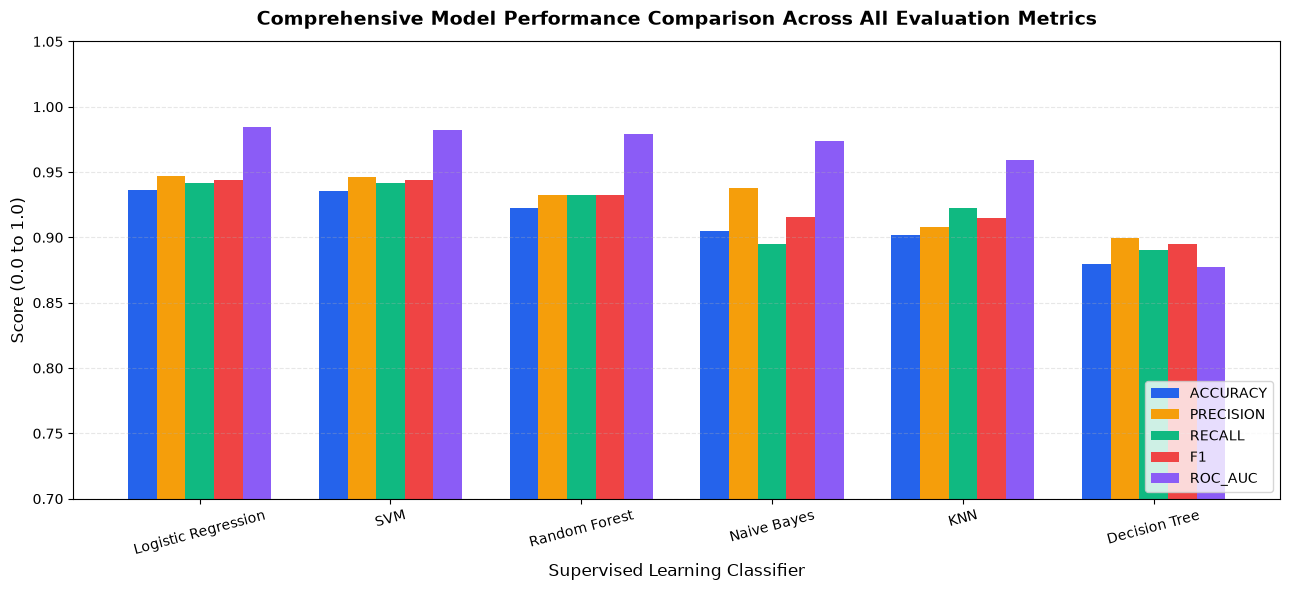

In [11]:
# Comprehensive Multi-Metric Comparison Chart Across All 6 Models
eval_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
x = np.arange(len(metrics))
width = 0.15
metric_colors = ['#2563eb', '#f59e0b', '#10b981', '#ef4444', '#8b5cf6']

plt.figure(figsize=(13, 6))
for i, m_name in enumerate(eval_metrics):
    vals = metrics[m_name].values
    plt.bar(x + i * width, vals, width, label=m_name.upper(), color=metric_colors[i])

plt.title('Comprehensive Model Performance Comparison Across All Evaluation Metrics', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Supervised Learning Classifier', fontsize=12)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
plt.xticks(x + width * 2, metrics['model'], rotation=15, fontsize=10)
plt.ylim(0.7, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## Step 8 - Model Evaluation: Confusion Matrix, ROC Curve & Feature Importance


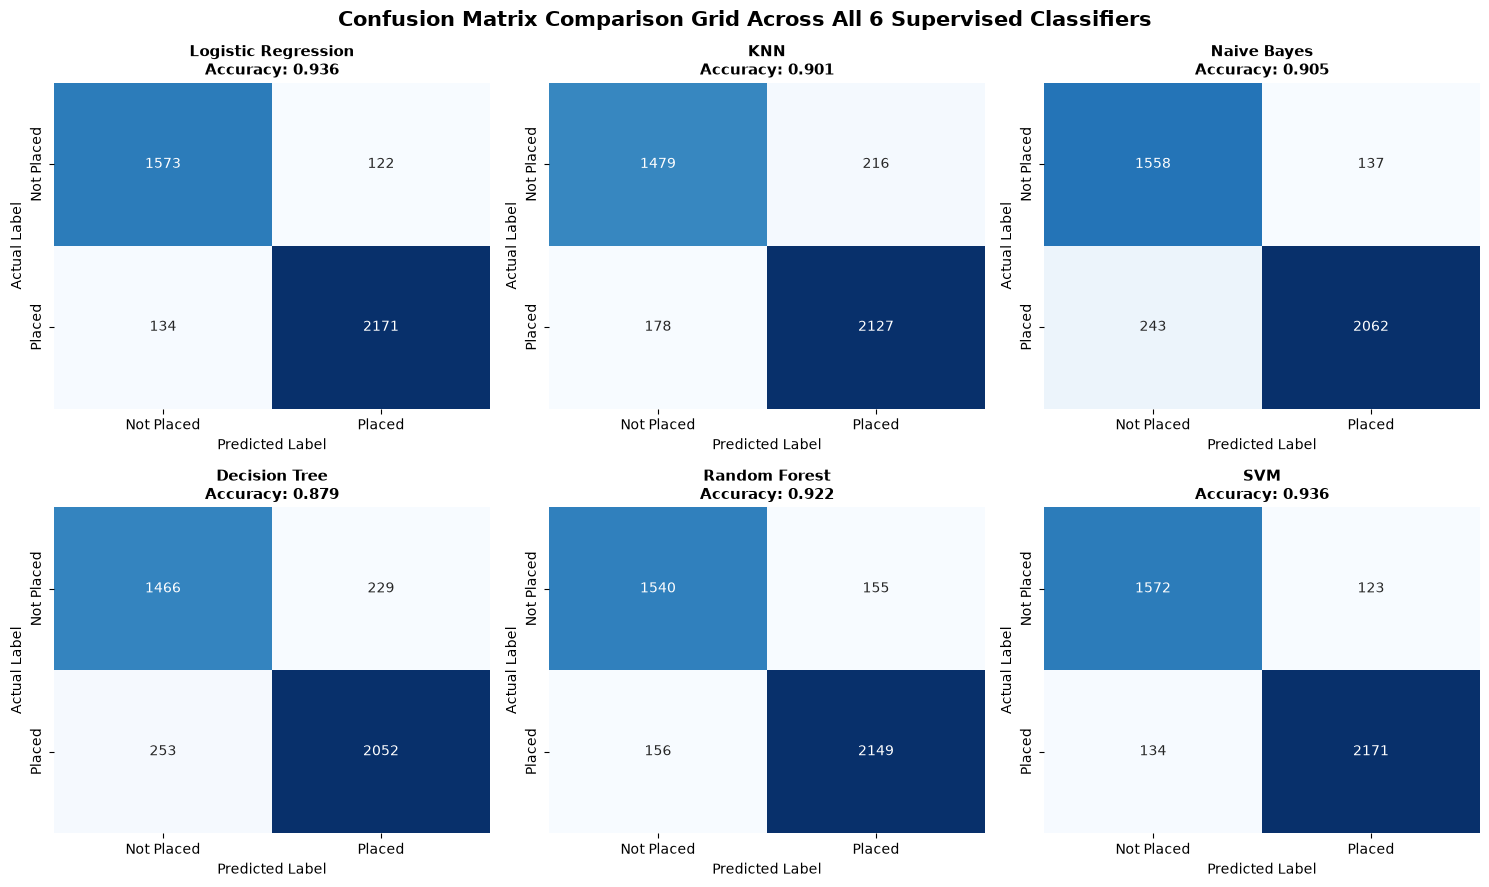

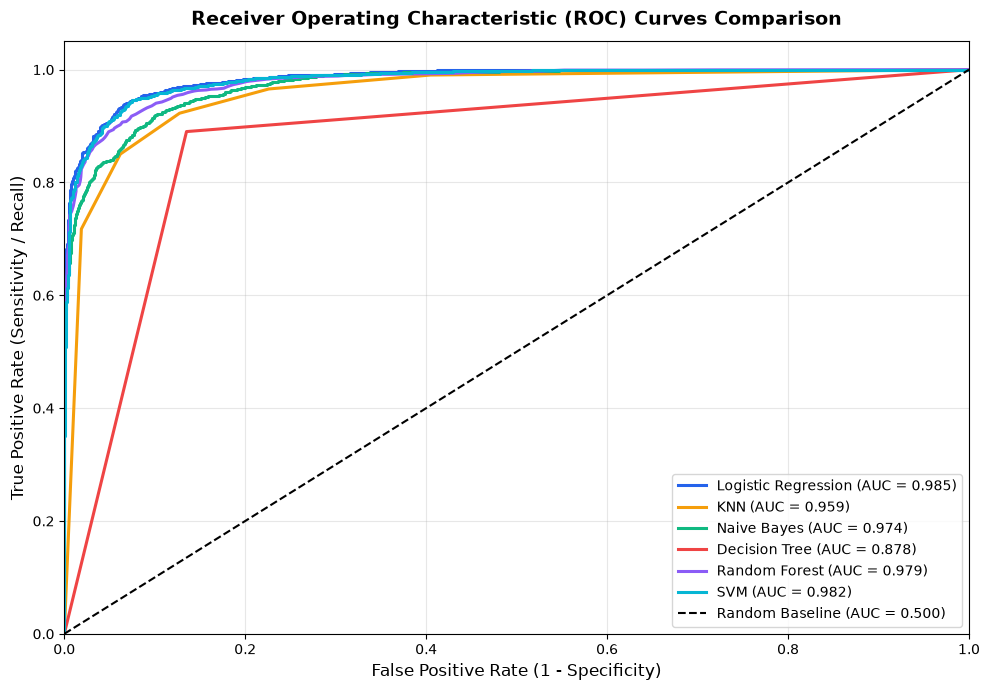

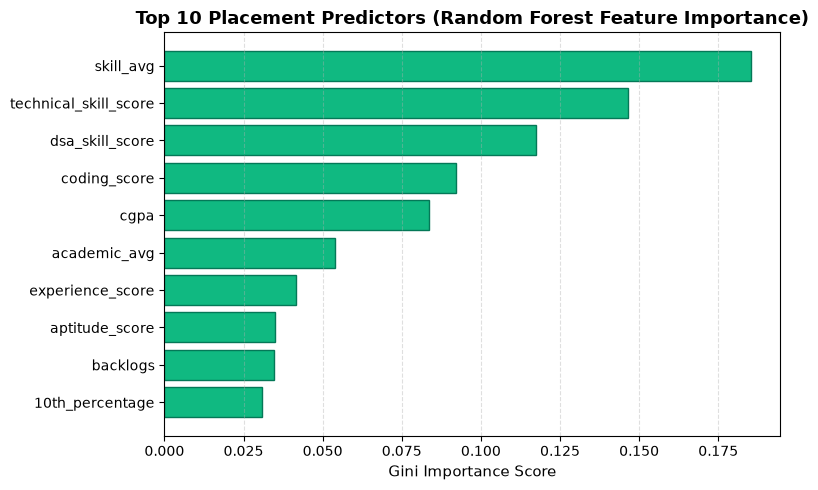

In [ ]:
# 1. 2x3 Confusion Matrix Grid Across All 6 Models (Syllabus Unit 2 Requirement)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
model_order = list(models.keys())

for i, name in enumerate(model_order):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['Not Placed', 'Placed'], yticklabels=['Not Placed', 'Placed'])
    cur_acc = accuracy_score(y_test, predictions[name])
    axes[i].set_title(f"{name}\nAccuracy: {cur_acc:.3f}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label')

plt.suptitle('Confusion Matrix Comparison Grid Across All 6 Supervised Classifiers', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# 2. Combined ROC Curves Comparison Graph Across All 6 Models (Syllabus Unit 2 Requirement)
plt.figure(figsize=(10, 7))
roc_palette = ['#2563eb', '#f59e0b', '#10b981', '#ef4444', '#8b5cf6', '#06b6d4']

for (name, y_prob), col in zip(probabilities.items(), roc_palette):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, color=col, lw=2.2, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Baseline (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)    
plt.title('Receiver Operating Characteristic (ROC) Curves Comparison', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Top 10 Feature Importances (Random Forest - Syllabus Unit 3 Requirement)
top10 = importance.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top10['feature'], top10['importance'], color='#10b981', edgecolor='#047857')
plt.xlabel('Gini Importance Score', fontsize=11)
plt.title('Top 10 Placement Predictors (Random Forest Feature Importance)', fontsize=13, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


## Step 9 - Predict Placement for a New Student
Demonstrating real-time prediction using the best-performing trained model on a sample student profile.


In [13]:
best_model = trained[winner]

new_student = pd.DataFrame([{
    "age": 21,
    "gender": "Male",
    "cgpa": 8.5,
    "10th_percentage": 50.0,
    "12th_percentage": 35.0,
    "backlogs": 1,
    "attendance_percentage": 88.0,
    "coding_score": 25.0,
    "aptitude_score": 28.0,
    "communication_score": 75.0,
    "technical_skill_score": 80.0,
    "number_of_projects": 5,
    "internship_months": 6,
    "certifications": 2,
    "hackathon_participation": 2,
    "programming_languages_known": 4,
    "dsa_skill_score": 82.0,
    "database_skill_score": 80.0,
    "web_development_skill": 78.0,
    "github_projects": 5,
    "extracurricular_score": 80.0
}])

skill_cols = ["coding_score", "aptitude_score", "communication_score",
              "technical_skill_score", "dsa_skill_score",
              "database_skill_score", "web_development_skill"]

new_student["academic_avg"] = (new_student["cgpa"] * 10 + new_student["10th_percentage"] + new_student["12th_percentage"]) / 3
new_student["skill_avg"] = new_student[skill_cols].mean(axis=1)
new_student["experience_score"] = (new_student["internship_months"] + new_student["number_of_projects"] +
                                     new_student["certifications"] + new_student["hackathon_participation"] +
                                     new_student["github_projects"])

new_student = pd.get_dummies(new_student, columns=["gender"], drop_first=True)
new_student = new_student.reindex(columns=feature_names, fill_value=0)

new_student_scaled = scaler.transform(new_student)
prediction = best_model.predict(new_student_scaled)[0]
status_str = "Placed" if prediction == 1 else "Not Placed"

print("=== PREDICTION RESULT ===")
print(f"Best Model Used: {winner}")
print(f"Prediction: {status_str}")
if hasattr(best_model, "predict_proba"):
    prob = best_model.predict_proba(new_student_scaled)[0][1]
    print(f"Placement Probability: {prob * 100:.2f}%")


=== PREDICTION RESULT ===
Best Model Used: Logistic Regression
Prediction: Placed
Placement Probability: 81.80%


## Viva Q&A Reference

- **What is the goal of this system?** It predicts whether a student will be Placed or Not Placed based on academics, technical skills, and experience, identifying key factors for placement.
- **What feature engineering was performed?** Domain aggregations: `academic_avg` (combining CGPA, 10th, 12th), `skill_avg` (mean of core technical skills), and `experience_score` (projects, internships, hackathons, certifications).
- **Why use feature scaling (StandardScaler)?** Distance- and margin-based algorithms like KNN, Logistic Regression, and SVM depend heavily on feature magnitude. Standardization ensures fair weighting.
- **Why split data into Train and Test sets?** To evaluate model generalization on unseen data and detect overfitting.
- **Which metrics were used for evaluation?** Accuracy, Precision, Recall, F1-score, Confusion Matrix, and ROC-AUC curve.
- **What is the advantage of F1-score over Accuracy?** F1-score balances precision and recall, providing a more reliable metric when classes might be imbalanced.
- **How are predictions made for a new student?** The raw inputs undergo identical feature engineering and standardization with the fitted `StandardScaler`, and are passed to the best-performing classifier (`Logistic Regression`).
